# 03 — Classification: Wine Type

## 1. Pendahuluan

Notebook ini bertujuan membangun model *machine learning* untuk mengklasifikasikan jenis wine berdasarkan karakteristik fisikokimia. Klasifikasi dilakukan terhadap dua kategori, yaitu red wine dan white wine.

Dataset yang digunakan merupakan hasil pembersihan pada tahap Data Preparation dan analisis pada tahap Exploratory Data Analysis (EDA).

Eksperimen ini mencakup pemisahan fitur dan target, pembagian data latih dan data uji, preprocessing, pelatihan model klasifikasi, serta evaluasi performa model.

## 2. Tujuan Eksperimen

1. Memahami penerapan klasifikasi biner menggunakan *machine learning*.
2. Membangun model untuk membedakan red wine dan white wine.
3. Mengevaluasi performa model menggunakan metrik klasifikasi.
4. Membandingkan performa beberapa algoritma untuk menentukan model yang sesuai dengan dataset.

In [2]:
# 1. Import library

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Library berhasil diimpor.")

Library berhasil diimpor.


In [3]:
# 2. Memuat dataset bersih

filename = "winequality_cleaned.csv"

possible_paths = [
    Path.cwd() / "data" / "processed" / filename,
    Path.cwd().parent / "data" / "processed" / filename,
]

DATA_PATH = next(
    (path for path in possible_paths if path.exists()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError(
        f"{filename} tidak ditemukan. "
        "Periksa lokasi folder data/processed."
    )

df = pd.read_csv(DATA_PATH)

print("Lokasi dataset:", DATA_PATH)
print("Ukuran dataset:", df.shape)

display(df.head())

Lokasi dataset: d:\MachineLearning\Wine\data\processed\winequality_cleaned.csv
Ukuran dataset: (5320, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,0


In [4]:
# 3. Memisahkan fitur dan target

feature_cols = [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol",
]

X = df[feature_cols]
y = df["wine_type"]

print("Ukuran fitur X:", X.shape)
print("Ukuran target y:", y.shape)

print("\nDistribusi target:")
display(
    y.value_counts()
    .sort_index()
    .rename(index={0: "Red wine", 1: "White wine"})
    .to_frame("jumlah")
)

print("\nContoh fitur:")
display(X.head())

print("\nContoh target:")
display(y.head())

Ukuran fitur X: (5320, 11)
Ukuran target y: (5320,)

Distribusi target:


,jumlah
wine_type,
Red wine,1359
White wine,3961



Contoh fitur:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4



Contoh target:


0    0
1    0
2    0
3    0
4    0
Name: wine_type, dtype: int64

## 4. Pembagian Data Latih dan Data Uji

Pada tahap ini, dataset dibagi menjadi data latih (*training data*) dan data uji (*testing data*). Data latih digunakan untuk membangun model, sedangkan data uji digunakan untuk mengevaluasi performa model terhadap data yang tidak digunakan selama pelatihan.

Pembagian dilakukan dengan proporsi 80% untuk data latih dan 20% untuk data uji. Parameter `stratify=y` digunakan untuk mempertahankan proporsi setiap kelas pada kedua bagian data, sedangkan `random_state=42` memastikan pembagian data dapat direproduksi.

In [5]:

# 4. Membagi data latih dan data uji

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Ukuran data latih:", X_train.shape)
print("Ukuran data uji:", X_test.shape)

print("\nDistribusi kelas pada data latih:")
display(
    y_train.value_counts()
    .sort_index()
    .rename(index={0: "Red wine", 1: "White wine"})
    .to_frame("jumlah")
)

print("\nDistribusi kelas pada data uji:")
display(
    y_test.value_counts()
    .sort_index()
    .rename(index={0: "Red wine", 1: "White wine"})
    .to_frame("jumlah")
)

print("\nProporsi kelas pada data latih:")
display(y_train.value_counts(normalize=True).sort_index())

print("\nProporsi kelas pada data uji:")
display(y_test.value_counts(normalize=True).sort_index())


Ukuran data latih: (4256, 11)
Ukuran data uji: (1064, 11)

Distribusi kelas pada data latih:


,jumlah
wine_type,
Red wine,1087
White wine,3169



Distribusi kelas pada data uji:


,jumlah
wine_type,
Red wine,272
White wine,792



Proporsi kelas pada data latih:


wine_type
0    0.255404
1    0.744596
Name: proportion, dtype: float64


Proporsi kelas pada data uji:


wine_type
0    0.255639
1    0.744361
Name: proportion, dtype: float64

### 5.1 Pelatihan Model Logistic Regression

Pada tahap ini, algoritma Logistic Regression digunakan sebagai model klasifikasi awal untuk memprediksi jenis wine berdasarkan 11 fitur fisikokimia.

Sebelum pelatihan, fitur distandardisasi menggunakan `StandardScaler` agar perbedaan skala antarfitur tidak terlalu memengaruhi proses pembelajaran model. Standardisasi dilakukan melalui `Pipeline`, sehingga proses penskalaan dipelajari dari data latih saja dan kemudian diterapkan pada data uji.

Model dilatih menggunakan data latih, sedangkan data uji disimpan untuk evaluasi performa setelah pelatihan selesai.

In [6]:

# 5. Melatih model Logistic Regression

model_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

model_lr.fit(X_train, y_train)

print("Model Logistic Regression berhasil dilatih.")


Model Logistic Regression berhasil dilatih.


In [7]:

# 5.3 Melakukan prediksi pada data uji

y_pred = model_lr.predict(X_test)

print("Lima label aktual pertama:")
print(y_test.iloc[:5].tolist())

print("\nLima hasil prediksi pertama:")
print(y_pred[:5])


Lima label aktual pertama:
[1, 0, 1, 1, 1]

Lima hasil prediksi pertama:
[1 0 1 1 1]


## 6. Evaluasi Performa Model

Evaluasi dilakukan menggunakan data uji yang tidak digunakan selama proses pelatihan. Metrik yang digunakan meliputi accuracy, precision, recall, dan F1-score.

Selain itu, confusion matrix digunakan untuk mengetahui jumlah prediksi benar dan salah pada setiap kelas. Penggunaan beberapa metrik diperlukan karena dataset memiliki distribusi kelas yang tidak seimbang, dengan jumlah white wine lebih banyak daripada red wine.

In [8]:

# 6.1 Menghitung metrik evaluasi

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy : {accuracy:.4f}")
print(f"Accuracy : {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Red wine", "White wine"],
        digits=4,
        zero_division=0
    )
)


Accuracy : 0.9934
Accuracy : 99.34%

Classification Report:
              precision    recall  f1-score   support

    Red wine     0.9889    0.9853    0.9871       272
  White wine     0.9950    0.9962    0.9956       792

    accuracy                         0.9934      1064
   macro avg     0.9919    0.9908    0.9913      1064
weighted avg     0.9934    0.9934    0.9934      1064



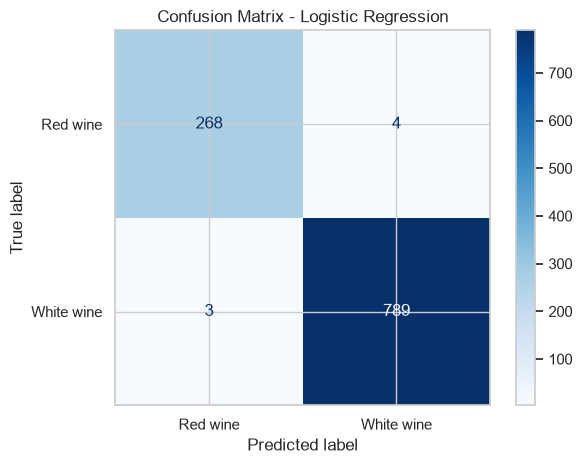

Confusion matrix:
[[268   4]
 [  3 789]]


In [9]:

# 6.2 Visualisasi confusion matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Red wine", "White wine"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

print("Confusion matrix:")
print(cm)


## 7. Klasifikasi Menggunakan Decision Tree

Pada tahap ini, algoritma Decision Tree digunakan sebagai model klasifikasi kedua untuk memprediksi jenis wine berdasarkan 11 fitur fisikokimia.

Decision Tree membentuk aturan keputusan berdasarkan pola pada data latih. Berbeda dengan Logistic Regression, algoritma ini dapat mempelajari pola nonlinier melalui pemisahan fitur secara bertahap.

Model dilatih menggunakan data latih dan dievaluasi menggunakan data uji yang sama dengan eksperimen Logistic Regression. Penggunaan data uji yang sama bertujuan menjaga konsistensi perbandingan performa antarmodel.

In [10]:

# 7.1 Melatih model Decision Tree

from sklearn.tree import DecisionTreeClassifier

model_dt = DecisionTreeClassifier(random_state=42)

model_dt.fit(X_train, y_train)

print("Model Decision Tree berhasil dilatih.")


Model Decision Tree berhasil dilatih.


In [11]:

# 7.2 Melakukan prediksi menggunakan Decision Tree

y_pred_dt = model_dt.predict(X_test)

print("Lima label aktual pertama:")
print(y_test.iloc[:5].tolist())

print("\nLima hasil prediksi Decision Tree:")
print(y_pred_dt[:5])


Lima label aktual pertama:
[1, 0, 1, 1, 1]

Lima hasil prediksi Decision Tree:
[1 0 1 1 1]


In [12]:

# 7.3 Evaluasi model Decision Tree

accuracy_dt = accuracy_score(y_test, y_pred_dt)

print(f"Accuracy Decision Tree: {accuracy_dt:.4f}")
print(f"Accuracy Decision Tree: {accuracy_dt * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_dt,
        labels=[0, 1],
        target_names=["Red wine", "White wine"],
        digits=4,
        zero_division=0
    )
)


Accuracy Decision Tree: 0.9765
Accuracy Decision Tree: 97.65%

Classification Report:
              precision    recall  f1-score   support

    Red wine     0.9491    0.9596    0.9543       272
  White wine     0.9861    0.9823    0.9842       792

    accuracy                         0.9765      1064
   macro avg     0.9676    0.9709    0.9692      1064
weighted avg     0.9766    0.9765    0.9765      1064



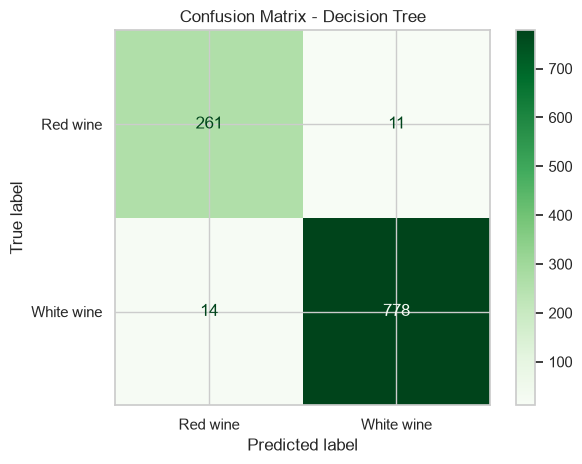

Confusion matrix Decision Tree:
[[261  11]
 [ 14 778]]


In [13]:

# 7.4 Confusion matrix Decision Tree

cm_dt = confusion_matrix(y_test, y_pred_dt, labels=[0, 1])

disp_dt = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=["Red wine", "White wine"]
)

disp_dt.plot(cmap="Greens", values_format="d")
plt.title("Confusion Matrix - Decision Tree")
plt.tight_layout()
plt.show()

print("Confusion matrix Decision Tree:")
print(cm_dt)


## 8. Klasifikasi Menggunakan K-Nearest Neighbors (KNN)

K-Nearest Neighbors (KNN) merupakan algoritma klasifikasi yang menentukan kelas suatu sampel berdasarkan kelas dari sejumlah tetangga terdekatnya.

Dalam eksperimen ini, KNN digunakan untuk memprediksi jenis wine berdasarkan 11 fitur fisikokimia. Standardisasi fitur dilakukan menggunakan StandardScaler agar perbedaan skala antarfitur tidak mendominasi perhitungan jarak.

Model akan dilatih dan dievaluasi menggunakan pembagian data latih dan data uji yang sama dengan dua eksperimen sebelumnya.

In [14]:

# 8.1 Melatih model KNN

from sklearn.neighbors import KNeighborsClassifier

model_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

model_knn.fit(X_train, y_train)

print("Model KNN berhasil dilatih.")


Model KNN berhasil dilatih.


In [15]:

# 8.2 Melakukan prediksi menggunakan KNN

y_pred_knn = model_knn.predict(X_test)

print("Lima label aktual pertama:")
print(y_test.iloc[:5].tolist())

print("\nLima hasil prediksi KNN:")
print(y_pred_knn[:5])


Lima label aktual pertama:
[1, 0, 1, 1, 1]

Lima hasil prediksi KNN:
[1 0 1 1 1]


In [16]:

# 8.3 Evaluasi model KNN

accuracy_knn = accuracy_score(y_test, y_pred_knn)

print(f"Accuracy KNN: {accuracy_knn:.4f}")
print(f"Accuracy KNN: {accuracy_knn * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_knn,
        labels=[0, 1],
        target_names=["Red wine", "White wine"],
        digits=4,
        zero_division=0
    )
)


Accuracy KNN: 0.9934
Accuracy KNN: 99.34%

Classification Report:
              precision    recall  f1-score   support

    Red wine     0.9889    0.9853    0.9871       272
  White wine     0.9950    0.9962    0.9956       792

    accuracy                         0.9934      1064
   macro avg     0.9919    0.9908    0.9913      1064
weighted avg     0.9934    0.9934    0.9934      1064



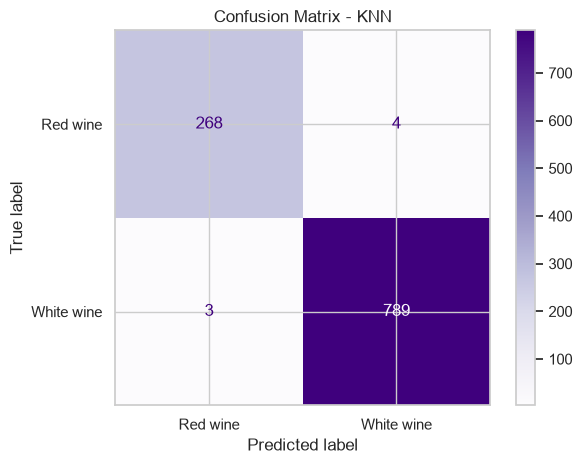

Confusion matrix KNN:
[[268   4]
 [  3 789]]


In [17]:

# 8.4 Confusion matrix KNN

cm_knn = confusion_matrix(y_test, y_pred_knn, labels=[0, 1])

disp_knn = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=["Red wine", "White wine"]
)

disp_knn.plot(cmap="Purples", values_format="d")
plt.title("Confusion Matrix - KNN")
plt.tight_layout()
plt.show()

print("Confusion matrix KNN:")
print(cm_knn)


In [18]:
# 8.5 Random Forest Classifier

# Inisialisasi model
rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# Melatih model menggunakan data training
rf_model.fit(X_train, y_train)

# Prediksi data testing
y_pred_rf = rf_model.predict(X_test)

print("Random Forest berhasil dilatih!")

Random Forest berhasil dilatih!


In [30]:
# 8.6 Evaluasi Model Random Forest

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

# Menghitung metrik evaluasi
accuracy_rf = accuracy_score(y_test, y_pred_rf)
f1_macro_rf = f1_score(y_test, y_pred_rf, average="macro")

print("=== Evaluasi Random Forest ===")
print(f"Accuracy  : {accuracy_rf:.4f} ({accuracy_rf * 100:.2f}%)")
print(f"Macro F1  : {f1_macro_rf:.4f} ({f1_macro_rf * 100:.2f}%)")

print("\n=== Classification Report ===")
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["Red Wine", "White Wine"],
        digits=4
    )
)

=== Evaluasi Random Forest ===
Accuracy  : 0.9934 (99.34%)
Macro F1  : 0.9913 (99.13%)

=== Classification Report ===
              precision    recall  f1-score   support

    Red Wine     0.9889    0.9853    0.9871       272
  White Wine     0.9950    0.9962    0.9956       792

    accuracy                         0.9934      1064
   macro avg     0.9919    0.9908    0.9913      1064
weighted avg     0.9934    0.9934    0.9934      1064



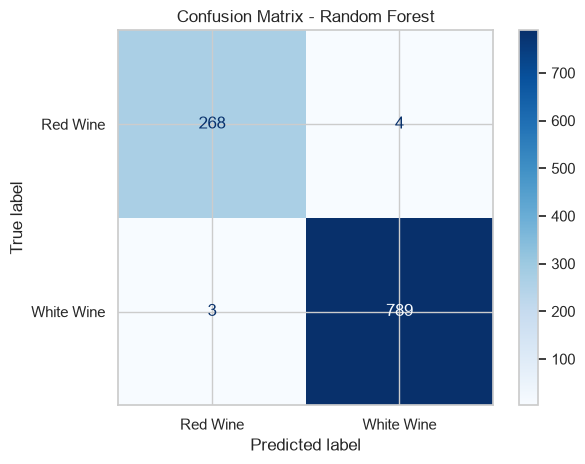

In [31]:
# 8.7 Confusion Matrix Random Forest

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

cm_rf = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Red Wine", "White Wine"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Random Forest")
plt.tight_layout()
plt.show()

## 9. Perbandingan Performa Model Klasifikasi

Pada tahap ini, performa Logistic Regression, Decision Tree, dan K-Nearest Neighbors (KNN) dibandingkan menggunakan accuracy, precision, recall, dan F1-score. Seluruh model dievaluasi pada data uji yang sama agar perbandingan lebih konsisten.

Perbandingan dilakukan untuk mengetahui model yang memberikan performa terbaik dalam mengklasifikasikan red wine dan white wine berdasarkan fitur fisikokimia.

In [19]:

# 9.1 Membandingkan performa ketiga model

models = {
    "Logistic Regression": y_pred,
    "Decision Tree": y_pred_dt,
    "KNN": y_pred_knn,
}

comparison_results = []

for model_name, predictions in models.items():
    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (Macro)": __import__(
            "sklearn.metrics", fromlist=["precision_score"]
        ).precision_score(y_test, predictions, average="macro"),
        "Recall (Macro)": __import__(
            "sklearn.metrics", fromlist=["recall_score"]
        ).recall_score(y_test, predictions, average="macro"),
        "F1-score (Macro)": f1_score(
            y_test, predictions, average="macro"
        ),
    })

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.style.format({
        "Accuracy": "{:.4%}",
        "Precision (Macro)": "{:.4%}",
        "Recall (Macro)": "{:.4%}",
        "F1-score (Macro)": "{:.4%}",
    })
)


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
0,Logistic Regression,99.3421%,99.1943%,99.0753%,99.1346%
1,Decision Tree,97.6504%,96.7575%,97.0941%,96.9242%
2,KNN,99.3421%,99.1943%,99.0753%,99.1346%


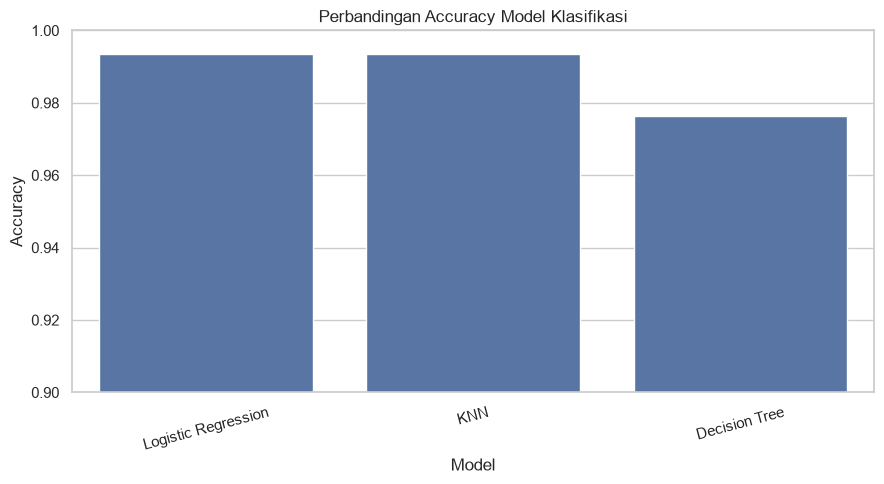

In [20]:

# 9.2 Visualisasi perbandingan accuracy

comparison_plot = comparison_df.sort_values(
    "Accuracy",
    ascending=False
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison_plot,
    x="Model",
    y="Accuracy"
)

plt.ylim(0.90, 1.00)
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.title("Perbandingan Accuracy Model Klasifikasi")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


Berdasarkan hasil pengujian pada 1.064 data uji, Logistic Regression dan K-Nearest Neighbors (KNN) memperoleh accuracy sebesar 99,34%, sedangkan Decision Tree memperoleh accuracy sebesar 97,65%. Logistic Regression dan KNN juga menghasilkan nilai precision, recall, serta F1-score yang sama pada hasil evaluasi ini.

Dengan demikian, Logistic Regression dan KNN menunjukkan performa terbaik berdasarkan metrik yang telah diamati, sementara Decision Tree memiliki performa yang lebih rendah pada pembagian data ini. Meskipun demikian, hasil tersebut belum membuktikan bahwa kedua model memiliki kemampuan generalisasi yang identik. Evaluasi lanjutan, seperti cross-validation dan pengujian beberapa nilai parameter KNN, dapat digunakan untuk memeriksa kestabilan performa model.

## 10. Evaluasi Model Menggunakan Cross-Validation

Cross-validation digunakan untuk mengevaluasi kestabilan performa model pada beberapa pembagian data. Pada eksperimen ini, digunakan Stratified 5-Fold Cross-Validation untuk mempertahankan proporsi kelas red wine dan white wine pada setiap fold.

Evaluasi dilakukan pada data latih. Data uji tetap dipisahkan untuk menjaga independensi evaluasi akhir. Metrik yang digunakan adalah accuracy, precision macro, recall macro, dan F1-score macro.

In [21]:

# 10.1 Cross-validation pada data latih

from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models_cv = {
    "Logistic Regression": model_lr,
    "Decision Tree": model_dt,
    "KNN (k=5)": model_knn,
}

scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
}

cv_results = []

for model_name, model in models_cv.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": model_name,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Precision Macro Mean": scores["test_precision_macro"].mean(),
        "Recall Macro Mean": scores["test_recall_macro"].mean(),
        "F1 Macro Mean": scores["test_f1_macro"].mean(),
    })

cv_df = pd.DataFrame(cv_results)

display(
    cv_df.style.format({
        "Accuracy Mean": "{:.4%}",
        "Accuracy Std": "{:.4%}",
        "Precision Macro Mean": "{:.4%}",
        "Recall Macro Mean": "{:.4%}",
        "F1 Macro Mean": "{:.4%}",
    })
)


,Model,Accuracy Mean,Accuracy Std,Precision Macro Mean,Recall Macro Mean,F1 Macro Mean
0,Logistic Regression,99.2482%,0.2417%,99.0750%,98.9513%,99.0097%
1,Decision Tree,97.7914%,0.4290%,97.1026%,97.1261%,97.1022%
2,KNN (k=5),99.0838%,0.3589%,98.8698%,98.7203%,98.7932%


## 11. Optimasi Parameter K pada KNN

Pada tahap ini, dilakukan pengujian beberapa nilai \(k\) pada algoritma K-Nearest Neighbors. Nilai \(k\) menentukan jumlah tetangga terdekat yang digunakan untuk menentukan kelas suatu sampel.

Pengujian dilakukan menggunakan Stratified 5-Fold Cross-Validation pada data latih. Pemilihan parameter didasarkan terutama pada nilai rata-rata F1 macro agar performa kedua kelas tetap diperhatikan, serta accuracy sebagai metrik pendukung.

Data uji tidak digunakan dalam pemilihan parameter sehingga tetap dapat digunakan untuk evaluasi akhir.

In [22]:

# 11.1 Menguji beberapa nilai k pada KNN

from sklearn.model_selection import cross_validate

k_values = range(1, 22, 2)

knn_tuning_results = []

for k in k_values:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=k))
    ])

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "f1_macro": "f1_macro"
        },
        n_jobs=-1
    )

    knn_tuning_results.append({
        "k": k,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "F1 Macro Mean": scores["test_f1_macro"].mean()
    })

knn_tuning_df = pd.DataFrame(knn_tuning_results)

display(
    knn_tuning_df.style.format({
        "Accuracy Mean": "{:.4%}",
        "Accuracy Std": "{:.4%}",
        "F1 Macro Mean": "{:.4%}"
    })
)


,k,Accuracy Mean,Accuracy Std,F1 Macro Mean
0,1,99.2717%,0.3006%,99.0423%
1,3,99.1073%,0.2834%,98.8245%
2,5,99.0838%,0.3589%,98.7932%
3,7,99.0368%,0.4226%,98.7329%
4,9,99.1073%,0.4368%,98.8249%
5,11,99.1308%,0.4107%,98.8564%
6,13,99.0838%,0.4893%,98.7933%
7,15,99.0368%,0.4418%,98.7326%
8,17,99.0603%,0.3929%,98.7636%
9,19,99.0603%,0.4392%,98.7639%


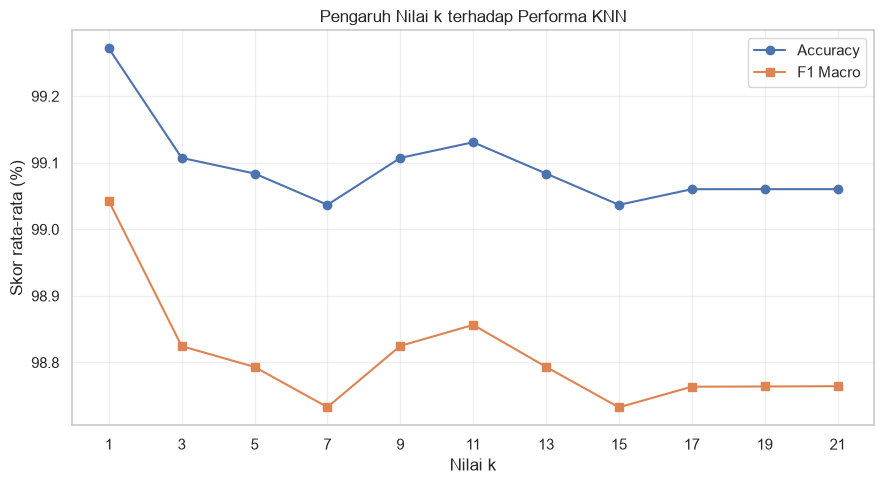

In [23]:

# 11.2 Grafik perbandingan nilai k

plt.figure(figsize=(9, 5))

plt.plot(
    knn_tuning_df["k"],
    knn_tuning_df["Accuracy Mean"] * 100,
    marker="o",
    label="Accuracy"
)

plt.plot(
    knn_tuning_df["k"],
    knn_tuning_df["F1 Macro Mean"] * 100,
    marker="s",
    label="F1 Macro"
)

plt.xlabel("Nilai k")
plt.ylabel("Skor rata-rata (%)")
plt.title("Pengaruh Nilai k terhadap Performa KNN")
plt.xticks(list(k_values))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [24]:

# 11.3 Mengurutkan kandidat berdasarkan F1 macro

knn_tuning_ranked = knn_tuning_df.sort_values(
    by=["F1 Macro Mean", "Accuracy Mean"],
    ascending=False
).reset_index(drop=True)

display(
    knn_tuning_ranked.style.format({
        "Accuracy Mean": "{:.4%}",
        "Accuracy Std": "{:.4%}",
        "F1 Macro Mean": "{:.4%}"
    })
)

best_k = int(knn_tuning_ranked.loc[0, "k"])

print("Kandidat nilai k terbaik:", best_k)
print(
    "F1 macro rata-rata:",
    f"{knn_tuning_ranked.loc[0, 'F1 Macro Mean']:.4%}"
)
print(
    "Accuracy rata-rata:",
    f"{knn_tuning_ranked.loc[0, 'Accuracy Mean']:.4%}"
)


,k,Accuracy Mean,Accuracy Std,F1 Macro Mean
0,1,99.2717%,0.3006%,99.0423%
1,11,99.1308%,0.4107%,98.8564%
2,9,99.1073%,0.4368%,98.8249%
3,3,99.1073%,0.2834%,98.8245%
4,13,99.0838%,0.4893%,98.7933%
5,5,99.0838%,0.3589%,98.7932%
6,21,99.0603%,0.4516%,98.7643%
7,19,99.0603%,0.4392%,98.7639%
8,17,99.0603%,0.3929%,98.7636%
9,7,99.0368%,0.4226%,98.7329%


Kandidat nilai k terbaik: 1
F1 macro rata-rata: 99.0423%
Accuracy rata-rata: 99.2717%


### 11.4 Pemilihan Parameter K Terbaik

Berdasarkan pengujian menggunakan Stratified 5-Fold Cross-Validation terhadap nilai \(k=1,3,5,\ldots,21\), nilai \(k=1\) menghasilkan rata-rata F1 macro tertinggi sebesar 99,0423% dan rata-rata accuracy sebesar 99,2717%.

Oleh karena itu, \(k=1\) dipilih sebagai kandidat parameter terbaik dari rentang yang diuji. Pemilihan ini didasarkan pada hasil cross-validation, sedangkan performa akhirnya akan dievaluasi menggunakan data uji yang tidak digunakan selama proses pemilihan parameter.

In [25]:

# 11.4 Melatih KNN dengan nilai k terbaik

best_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(n_neighbors=best_k))
])

best_knn.fit(X_train, y_train)

print("Nilai k terpilih:", best_k)
print("Model KNN terbaik berhasil dilatih.")


Nilai k terpilih: 1
Model KNN terbaik berhasil dilatih.


In [26]:

# 11.5 Evaluasi KNN dengan k terbaik pada data uji

y_pred_best_knn = best_knn.predict(X_test)

print("Accuracy:", f"{accuracy_score(y_test, y_pred_best_knn):.4%}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_best_knn,
        labels=[0, 1],
        target_names=["Red wine", "White wine"],
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_best_knn, labels=[0, 1]))


Accuracy: 99.5301%

Classification Report:
              precision    recall  f1-score   support

    Red wine     0.9926    0.9890    0.9908       272
  White wine     0.9962    0.9975    0.9968       792

    accuracy                         0.9953      1064
   macro avg     0.9944    0.9932    0.9938      1064
weighted avg     0.9953    0.9953    0.9953      1064


Confusion Matrix:
[[269   3]
 [  2 790]]


### 11.6 Analisis Hasil KNN dengan Parameter Terbaik

Berdasarkan proses tuning menggunakan Stratified 5-Fold Cross-Validation, parameter \(k=1\) dipilih sebagai kandidat terbaik dari rentang nilai yang diuji. Model KNN kemudian dilatih menggunakan data latih dan dievaluasi pada data uji yang belum digunakan dalam proses pemilihan parameter.

Hasil evaluasi menunjukkan bahwa model memperoleh accuracy sebesar **99,53%**, dengan macro precision sebesar **99,44%**, macro recall sebesar **99,32%**, dan macro F1-score sebesar **99,38%**. Berdasarkan confusion matrix, model berhasil mengklasifikasikan 1.059 dari 1.064 data uji dengan benar, sedangkan 5 data lainnya salah diklasifikasikan.

Dibandingkan dengan model KNN awal menggunakan \(k=5\), penggunaan \(k=1\) meningkatkan accuracy dari 99,34% menjadi 99,53% dan mengurangi jumlah kesalahan prediksi dari 7 menjadi 5. Hasil tersebut menunjukkan bahwa \(k=1\) memberikan performa lebih baik pada data uji dalam eksperimen ini.

Meskipun demikian, pemilihan parameter \(k=1\) perlu mempertimbangkan sensitivitas KNN terhadap noise. Oleh karena itu, hasil evaluasi ini menunjukkan performa model pada dataset dan pembagian data yang digunakan, bukan jaminan bahwa model akan memperoleh akurasi yang sama pada seluruh data wine yang belum pernah diamati.

In [27]:

# 12.1 Perbandingan akhir model klasifikasi

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Menghasilkan prediksi dari setiap model pada data uji
y_pred_lr = model_lr.predict(X_test)
y_pred_dt = model_dt.predict(X_test)
y_pred_knn_best = best_knn.predict(X_test)

# Mengumpulkan hasil prediksi
models = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "KNN (k=1)": y_pred_knn_best
}

# Menghitung metrik evaluasi
comparison_results = []

for model_name, predictions in models.items():
    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision Macro": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Recall Macro": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "F1-score Macro": f1_score(
            y_test, predictions, average="macro", zero_division=0
        )
    })

comparison_df = pd.DataFrame(comparison_results)

# Mengurutkan berdasarkan F1-score macro tertinggi
comparison_df = comparison_df.sort_values(
    by="F1-score Macro", ascending=False
).reset_index(drop=True)

comparison_df


,Model,Accuracy,Precision Macro,Recall Macro,F1-score Macro
0,KNN (k=1),0.995301,0.994418,0.993223,0.993819
1,Logistic Regression,0.993421,0.991943,0.990753,0.991346
2,Decision Tree,0.976504,0.967575,0.970941,0.969242


In [28]:

# 12.2 Menampilkan hasil dalam format persentase

comparison_display = comparison_df.copy()

metric_columns = [
    "Accuracy",
    "Precision Macro",
    "Recall Macro",
    "F1-score Macro"
]

comparison_display[metric_columns] = (
    comparison_display[metric_columns] * 100
).round(2)

comparison_display


,Model,Accuracy,Precision Macro,Recall Macro,F1-score Macro
0,KNN (k=1),99.53,99.44,99.32,99.38
1,Logistic Regression,99.34,99.19,99.08,99.13
2,Decision Tree,97.65,96.76,97.09,96.92


### 13. Analisis Perbandingan Model Klasifikasi

Berdasarkan hasil evaluasi pada data uji, model K-Nearest Neighbor (KNN) dengan parameter \(k=1\) memperoleh performa terbaik dengan accuracy sebesar 99,53% dan macro F1-score sebesar 99,38%. Logistic Regression berada pada urutan kedua dengan accuracy 99,34% dan macro F1-score 99,13%. Sementara itu, Decision Tree memperoleh accuracy 97,65% dan macro F1-score 96,92%.

Hasil tersebut menunjukkan bahwa KNN dengan \(k=1\) memberikan kemampuan klasifikasi terbaik di antara ketiga model berdasarkan metrik evaluasi pada data uji. Meskipun demikian, selisih accuracy antara KNN dan Logistic Regression hanya sekitar 0,19 poin persentase. Oleh karena itu, keunggulan KNN pada eksperimen ini perlu diinterpretasikan berdasarkan dataset dan pembagian data yang digunakan.

Pada evaluasi sebelumnya menggunakan Stratified 5-Fold Cross-Validation, Logistic Regression memperoleh rata-rata accuracy sebesar 99,25%, sedangkan KNN dengan \(k=5\) memperoleh 99,08% dan Decision Tree 97,79%. Karena parameter KNN kemudian dioptimalkan menjadi \(k=1\), hasil cross-validation KNN tersebut belum dapat digunakan sebagai perbandingan langsung dengan KNN terbaik.

Dengan demikian, KNN dengan \(k=1\) menjadi model dengan performa tertinggi pada evaluasi data uji dalam eksperimen ini. Untuk memperkuat kesimpulan pemilihan model, hasil cross-validation KNN dengan parameter \(k=1\) perlu dibandingkan kembali dengan kedua model lainnya menggunakan skema evaluasi yang sama.

In [29]:

# 14. Cross-validation akhir dengan parameter KNN terbaik

models_final_cv = {
    "Logistic Regression": model_lr,
    "Decision Tree": model_dt,
    "KNN (k=1)": best_knn
}

cv_results_final = []

for model_name, model in models_final_cv.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision_macro": "precision_macro",
            "recall_macro": "recall_macro",
            "f1_macro": "f1_macro"
        },
        n_jobs=-1
    )

    cv_results_final.append({
        "Model": model_name,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Precision Macro Mean": scores["test_precision_macro"].mean(),
        "Recall Macro Mean": scores["test_recall_macro"].mean(),
        "F1 Macro Mean": scores["test_f1_macro"].mean()
    })

cv_final_df = pd.DataFrame(cv_results_final)

cv_final_df.sort_values(
    by="F1 Macro Mean",
    ascending=False
).reset_index(drop=True)


,Model,Accuracy Mean,Accuracy Std,Precision Macro Mean,Recall Macro Mean,F1 Macro Mean
0,KNN (k=1),0.992717,0.003006,0.990580,0.990277,0.990423
1,Logistic Regression,0.992482,0.002417,0.990750,0.989513,0.990097
2,Decision Tree,0.977914,0.004290,0.971026,0.971261,0.971022


### 15. Kesimpulan Klasifikasi Jenis Wine

Berdasarkan eksperimen klasifikasi menggunakan Logistic Regression, Decision Tree, dan K-Nearest Neighbor (KNN), ketiga model mampu mengklasifikasikan jenis wine berdasarkan karakteristik fisikokimia dengan performa yang tinggi. Namun, terdapat perbedaan hasil di antara ketiga model.

KNN dengan parameter \(k=1\) memperoleh rata-rata accuracy cross-validation sebesar 99,27% dan rata-rata macro F1-score sebesar 99,04%. Pada evaluasi data uji, model ini menghasilkan accuracy sebesar 99,53% dan macro F1-score sebesar 99,38%, dengan 1.059 dari 1.064 prediksi yang benar.

Logistic Regression memperoleh rata-rata accuracy cross-validation sebesar 99,25% dan accuracy data uji sebesar 99,34%. Sementara itu, Decision Tree menghasilkan rata-rata accuracy cross-validation sebesar 97,79% dan accuracy data uji sebesar 97,65%.

Dengan mempertimbangkan hasil cross-validation dan evaluasi data uji, KNN dengan \(k=1\) menjadi model dengan performa terbaik dalam eksperimen klasifikasi ini. Meskipun demikian, selisih performanya terhadap Logistic Regression relatif kecil. Logistic Regression juga menunjukkan variasi accuracy antarfold yang lebih rendah. Oleh karena itu, pemilihan model terbaik didasarkan pada metrik evaluasi yang diperoleh, bukan pada anggapan bahwa satu algoritma selalu lebih unggul daripada algoritma lainnya.

Hasil ini menunjukkan bahwa sebelas karakteristik fisikokimia yang digunakan memiliki kemampuan yang sangat baik untuk membedakan Red wine dan White wine pada dataset yang dianalisis. Hasil tersebut tetap perlu dipahami dalam konteks dataset, proses prapemrosesan, dan pembagian data yang digunakan dalam penelitian ini.